# Exercise 3: Neural networks in PyTorch

In this exercise you’ll implement small neural-network building blocks from scratch and use them to train a simple classifier.

You’ll cover:
- **Basic layers**: Linear, Embedding, Dropout
- **Normalization**: LayerNorm and RMSNorm
- **MLPs + residual**: composing layers into deeper networks
- **Classification**: generating a learnable dataset, implementing cross-entropy from logits, and writing a minimal training loop

As before: fill in all `TODO`s without changing function names or signatures.
Use small sanity checks and compare to PyTorch reference implementations when useful.

In [1]:
from __future__ import annotations

import torch
from torch import nn

## Basic layers

In this section you’ll implement a few core layers that appear everywhere:

### `Linear`
A fully-connected layer that follows nn.Linear conventions:  
`y = x @ Wᵀ + b`

Important details:
- Parameters should be registered as `nn.Parameter`
- Store weight as (out_features, in_features) like nn.Linear.
- The forward pass should support leading batch dimensions: `x` can be shape `(..., in_features)`

### `Embedding`
An embedding table maps integer ids to vectors:
- input: token ids `idx` of shape `(...,)`
- output: vectors of shape `(..., embedding_dim)`

This is essentially a learnable lookup table.

### `Dropout`
Dropout randomly zeroes activations during training to reduce overfitting.
Implementation details:
- Only active in `model.train()` mode
- In training: drop with probability `p` and scale the kept values by `1/(1-p)` so the expected value stays the same
- In eval: return the input unchanged

## Instructions
- Do not use PyTorch reference modules for the parts you implement (e.g. don’t call nn.Linear inside your Linear).
- You may use standard tensor ops that you learned before (matmul, sum, mean, rsqrt, indexing, etc.).
- Use a parameter initialization method of your choice. We recommend something like Xavier-uniform.


In [19]:
class Linear(nn.Module):
    def __init__(self, in_features: int, out_features: int, bias: bool = True):
        super().__init__()
        # TODO: initialize parameters

        self.weight = nn.Parameter(torch.empty(out_features, in_features))
        nn.init.xavier_uniform_(self.weight)
        if bias:
            self.bias = nn.Parameter(torch.zeros(out_features))
        else:
            self.register_parameter("bias", None)


    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        x: (..., in_features)
        return: (..., out_features)
        """
        # TODO: implement

        y = x @ self.weight.transpose(0, 1)
        return y if self.bias is None else y + self.bias



In [ ]:
class Embedding(nn.Module):
    def __init__(self, num_embeddings: int, embedding_dim: int):
        super().__init__()
        # TODO: initialize
        self.weight = nn.Parameter(torch.empty(num_embeddings, embedding_dim))
        nn.init.normal_(self.weight, mean=0.0, std=embedding_dim ** -0.5)

    def forward(self, idx: torch.Tensor) -> torch.Tensor:
        """
        idx: (...,) int64
        return: (..., embedding_dim)
        """
        # TODO: implement (index into weight)
        return self.weight[idx]

In [4]:
class Dropout(nn.Module):
    def __init__(self, p: float):
        super().__init__()

        if not 0.0 <= p <= 1.0:
            raise ValueError("p must be in [0, 1]")
        self.p = p

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        In train mode: drop with prob p and scale by 1/(1-p).
        In eval mode: return x unchanged.
        """
        # TODO: implement without using nn.Dropout

        if not self.training or self.p == 0.0:
            return x
        if self.p == 1.0:
            return x * 0
        keep = torch.rand_like(x) >= self.p # torch.rand_like()返回一个和 x 形状相同、dtype 相同、device 相同的新张量，里面填 [0, 1) 区间的均匀随机数。
        return x * keep.to(x.dtype) / (1.0 - self.p)


## Normalization

Normalization layers help stabilize training by controlling activation statistics.

### LayerNorm
LayerNorm normalizes each example across its **feature dimension** (the last dimension):

- compute mean and variance over the last dimension
- normalize: `(x - mean) / sqrt(var + eps)`
- apply learnable per-feature scale and shift (`weight`, `bias`)

**In this exercise, assume `elementwise_affine=True` (always include `weight` and `bias`).**  
`weight` and `bias` each have shape `(D,)`.

LayerNorm is widely used in transformers because it does not depend on batch statistics.

### RMSNorm
RMSNorm is similar to LayerNorm but normalizes using only the root-mean-square:
- `x / sqrt(mean(x^2) + eps)` over the last dimension
- usually includes a learnable scale (`weight`)
- no mean subtraction

RMSNorm is popular in modern LLMs because it's faster.


In [5]:
class LayerNorm(nn.Module):
    def __init__(
        self, normalized_shape: int, eps: float = 1e-5, elementwise_affine: bool = True
    ):
        super().__init__()
        # TODO: implement

        self.normalized_shape = normalized_shape
        self.eps = eps
        if elementwise_affine:
            self.weight = nn.Parameter(torch.ones(normalized_shape))
            self.bias = nn.Parameter(torch.zeros(normalized_shape))
        else:
            self.register_parameter("weight", None)
            self.register_parameter("bias", None)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Normalize over the last dimension.
        x: (..., D)
        """
        # TODO: implement

        if x.shape[-1] != self.normalized_shape:
            raise ValueError("last dimension must equal normalized_shape")
        mean = x.mean(dim=-1, keepdim=True)
        var = (x - mean).square().mean(dim=-1, keepdim=True)
        y = (x - mean) * torch.rsqrt(var + self.eps)
        if self.weight is not None:
            y = y * self.weight + self.bias
        return y


In [6]:
class RMSNorm(nn.Module):
    def __init__(self, normalized_shape: int, eps: float = 1e-8):
        super().__init__()
        # TODO: implement

        self.normalized_shape = normalized_shape
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(normalized_shape))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        RMSNorm: x / sqrt(mean(x^2) + eps) * weight
        over the last dimension.
        """
        # TODO: implement

        if x.shape[-1] != self.normalized_shape:
            raise ValueError("last dimension must equal normalized_shape")
        mean_square = x.square().mean(dim=-1, keepdim=True)
        return x * torch.rsqrt(mean_square + self.eps) * self.weight


## MLPs and residual networks

Now you’ll build larger networks by composing layers.

### MLP
An MLP is a stack of `depth` Linear layers with non-linear activations (use GELU) in between.
In this exercise you’ll support:
- configurable depth
- a hidden dimension
- optional LayerNorm between layers (a common stabilization trick)

A key skill is building networks using `nn.ModuleList` / `nn.Sequential` while keeping shapes consistent.

### Transformer-style FeedForward (FFN)
A transformer block contains a position-wise feedforward network:
- `D -> 4D -> D` (by default)
- activation is typically **GELU**

This is essentially an MLP applied independently at each token position.

### Residual wrapper
Residual connections are the simplest form of “skip connection”:
- output is `x + fn(x)`

They improve gradient flow and allow training deeper networks more reliably.

In [7]:
class MLP(nn.Module):
    def __init__(
        self,
        in_dim: int,
        hidden_dim: int,
        out_dim: int,
        depth: int,
        use_layernorm: bool = False,
    ):
        super().__init__()
        # TODO: build modules (list of Linear + activation)
        # Optionally insert LayerNorm between layers.

        if depth < 1:
            raise ValueError("depth must be at least 1")
        dims = [in_dim] + [hidden_dim] * (depth - 1) + [out_dim]
        layers = []
        for i in range(depth):
            layers.append(Linear(dims[i], dims[i + 1]))
            if i < depth - 1:
                if use_layernorm:
                    layers.append(LayerNorm(dims[i + 1]))
                layers.append(nn.GELU())
        self.net = nn.Sequential(*layers)


    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # TODO: implement
        return self.net(x)


In [8]:
class FeedForward(nn.Module):
    """
    Transformer-style FFN: D -> 4D -> D (default)
    """

    def __init__(self, d_model: int, d_ff: int | None = None):
        super().__init__()
        d_ff = d_ff or 4 * d_model
        # TODO: create two Linear layers and choose an activation (GELU)

        self.fc1 = Linear(d_model, d_ff)
        self.activation = nn.GELU()
        self.fc2 = Linear(d_ff, d_model)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # TODO: implement
        return self.fc2(self.activation(self.fc1(x)))


In [9]:
class Residual(nn.Module):
    def __init__(self, fn: nn.Module):
        super().__init__()
        # TODO: implement
        self.fn=fn

    def forward(self, x: torch.Tensor, *args, **kwargs) -> torch.Tensor:
        # TODO: return x + fn(x, ...)
        return x + self.fn(x, *args, **kwargs)


## Classification problem

In this section you’ll put everything together in a minimal MNIST classification experiment.

You will:
1) download and load the MNIST dataset
2) implement cross-entropy from logits (stable, using log-softmax)
3) build a simple MLP-based classifier (flatten MNIST images first)
4) write a minimal training loop
5) report train loss curve and final accuracy

The goal here is not to reach state-of-the-art accuracy, but to understand the full pipeline:
data → model → logits → loss → gradients → parameter update.

### Model notes
- We want you to combine the MLP we implemented above with the classification head we define below into one model 

### MNIST notes
- MNIST images are `28×28` grayscale.
- After `ToTensor()`, each image has shape `(1, 28, 28)` and values in `[0, 1]`.
- For an MLP classifier, we flatten to a vector of length `784`.

## Deliverables
- Include a plot of your train loss curve in the video submission as well as a final accuracy. 
- **NOTE** Here we don't grade on model performance but we expect you to achieve at least 70% accuracy to confirm a correct model implementation.

In [10]:
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

In [11]:
transform = transforms.ToTensor()  # -> float32 in [0,1], shape (1, 28, 28)

train_ds = datasets.MNIST(root="data", train=True, download=True, transform=transform)
test_ds  = datasets.MNIST(root="data", train=False, download=True, transform=transform)

# TODO: define the dataloaders
train_loader = DataLoader(train_ds, batch_size=128, shuffle=True, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=256, shuffle=False, num_workers=0)

In [12]:
def cross_entropy_from_logits(
    logits: torch.Tensor,
    targets: torch.Tensor,
) -> torch.Tensor:
    """
    Compute mean cross-entropy loss from logits.

    logits: (B, C)
    targets: (B,) int64

    Requirements:
    - Use log-softmax for stability (do not use torch.nn.CrossEntropyLoss, we check this in the autograder).
    """
    # TODO: implement
    log_probs = torch.log_softmax(logits,dim=-1)
    selected = log_probs.gather(1,targets.unsqueeze(1))
    return -selected.mean()

In [13]:
class ClassificationHead(nn.Module):
    def __init__(self, d_in: int, num_classes: int):
        super().__init__()
        # TODO: implement
        self.projection = Linear(d_in,num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        x: (..., d_in)
        return: (..., num_classes) logits
        """
        # TODO: implement
        return self.projection(x)

In [14]:
@torch.no_grad()
def _evaluate_classifier(model: nn.Module, loader: DataLoader) -> tuple[float, float]:
    device = next(model.parameters()).device
    was_training = model.training
    model.eval()
    total = 0
    correct = 0
    loss_sum = 0.0
    try:
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            n = yb.numel()
            loss_sum += cross_entropy_from_logits(logits, yb).item() * n
            correct += (logits.argmax(dim=-1) == yb).sum().item()
            total += n
    finally:
        model.train(was_training)
    if total == 0:
        raise ValueError("evaluation loader must not be empty")
    return loss_sum / total, correct / total

In [15]:
def accuracy(loader):
    # TODO: You can use this function to evaluate your model accuracy.
    return _evaluate_classifier(model, loader)[1]


In [16]:
def train_classifier(
    model: nn.Module,
    train_data_loader: DataLoader,
    test_data_loader: DataLoader,
    lr: float,
    epochs: int,
    seed: int = 0,
) -> list[float]:
    """
    Minimal training loop for MNIST classification.

    Steps:
    - define optimizer
    - for each epoch:
        - sample minibatches
        - forward -> cross-entropy -> backward -> optimizer step
      - compute test accuracy at the end of each epoch
    - return list of training losses (one per update step)

    Requirements:
    - call model.train() during training and model.eval() during evaluation
    - do not use torch.nn.CrossEntropyLoss (use your cross_entropy_from_logits)
    """
    # TODO: implement
    torch.manual_seed(seed)
    device = next(model.parameters()).device
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    train_losses = []
    history = {"train_loss": [], "test_loss": [], "test_accuracy": []}

    for epoch in range(epochs):
        model.train()
        loss_sum = 0.0
        total = 0
        for xb, yb in train_data_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(xb)
            loss = cross_entropy_from_logits(logits, yb)
            loss.backward()
            optimizer.step()
            train_losses.append(loss.item())
            n = yb.numel()
            loss_sum += loss.item() * n
            total += n
        if total == 0:
            raise ValueError("training loader must not be empty")
        test_loss, test_acc = _evaluate_classifier(model, test_data_loader)
        history["train_loss"].append(loss_sum / total)
        history["test_loss"].append(test_loss)
        history["test_accuracy"].append(test_acc)
        print(
            f"epoch {epoch + 1}/{epochs} | train loss {loss_sum / total:.4f} | "
            f"test loss {test_loss:.4f} | test accuracy {test_acc:.2%}"
        )

    model.training_history = history
    return train_losses


In [20]:

torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = nn.Sequential(
    nn.Flatten(start_dim=1),
    MLP(in_dim=784, hidden_dim=128, out_dim=128, depth=2, use_layernorm=True),
    nn.GELU(),
    ClassificationHead(d_in=128, num_classes=10),
).to(device)

train_losses = train_classifier(
    model, train_loader, test_loader, lr=1e-3, epochs=5, seed=0
)
final_accuracy = accuracy(test_loader)
print(f"Final test accuracy: {final_accuracy:.2%}")
print("Meets 70% requirement:", final_accuracy >= 0.70)


epoch 1/5 | train loss 0.2473 | test loss 0.1193 | test accuracy 96.30%
epoch 2/5 | train loss 0.0938 | test loss 0.0844 | test accuracy 97.34%
epoch 3/5 | train loss 0.0634 | test loss 0.0778 | test accuracy 97.34%
epoch 4/5 | train loss 0.0478 | test loss 0.0764 | test accuracy 97.52%
epoch 5/5 | train loss 0.0375 | test loss 0.0755 | test accuracy 97.53%
Final test accuracy: 97.53%
Meets 70% requirement: True


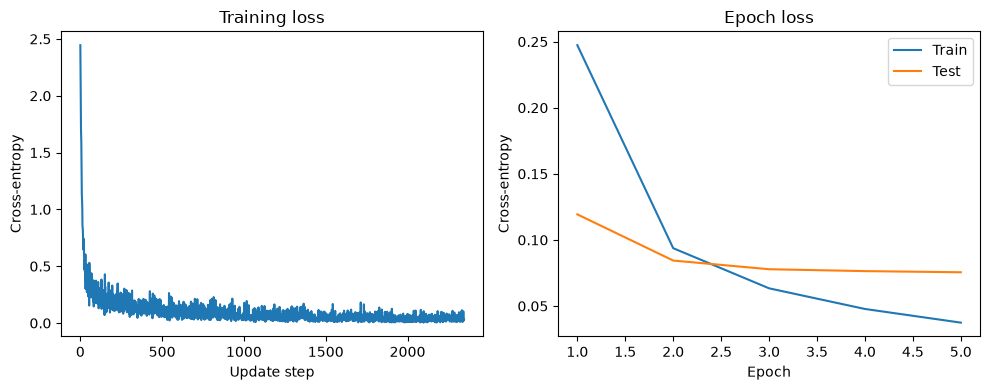

In [21]:
import matplotlib.pyplot as plt

history = model.training_history
epoch_axis = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(train_losses)
axes[0].set(xlabel="Update step", ylabel="Cross-entropy", title="Training loss")
axes[1].plot(epoch_axis, history["train_loss"], label="Train")
axes[1].plot(epoch_axis, history["test_loss"], label="Test")
axes[1].set(xlabel="Epoch", ylabel="Cross-entropy", title="Epoch loss")
axes[1].legend()
fig.tight_layout()
fig.savefig("ex3_loss_curves.png", dpi=160)
plt.show()